<a href="https://colab.research.google.com/github/hugolo000/DigitalImage_PROJECT/blob/main/notebooks/06_preprocessing_study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 - Preprocessing study
Our project asks how preprocessing (filtering, contrast enhancement) changes image quality and segmentation results.
Instead of applying generic filters, we:
1. measure what is actually wrong with the CamVid images,
2. choose filters that target these problems and show their effect on the images,
3. measure their effect on the classical segmentation of notebook 05 (same method, same test set).

This is the content of slide 5. Runs on CPU.

## 1. Setup
Same data loading and same functions as notebook 05 (copied here so this notebook runs on its own).

In [2]:
!pip install -q PyWavelets   # needed to estimate the noise level

import time
import zipfile
import urllib.request
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from skimage.segmentation import slic, mark_boundaries
from skimage.feature import local_binary_pattern
from skimage.restoration import estimate_sigma
from sklearn.ensemble import RandomForestClassifier

# Download and unzip CamVid
DATASET_URL = "https://github.com/alexgkendall/SegNet-Tutorial/archive/refs/heads/master.zip"
DATA_DIR = Path("./data")
RAW_ZIP_PATH = DATA_DIR / "camvid_raw.zip"
EXTRACTED_DIR = DATA_DIR / "extracted"

DATA_DIR.mkdir(parents=True, exist_ok=True)
if not RAW_ZIP_PATH.exists():
    print("[INFO] Downloading CamVid dataset...")
    urllib.request.urlretrieve(DATASET_URL, RAW_ZIP_PATH)
if not EXTRACTED_DIR.exists():
    print("[INFO] Unzipping dataset files...")
    with zipfile.ZipFile(RAW_ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACTED_DIR)

BASE_DIR = (EXTRACTED_DIR / "SegNet-Tutorial-master").resolve()
print("[INFO] Done.")

[INFO] Downloading CamVid dataset...
[INFO] Unzipping dataset files...
[INFO] Done.


In [3]:
def load_camvid_split(txt_filename, base_dir):
    """Reads a CamVid split file and returns a table with image and mask paths."""
    image_paths, mask_paths = [], []
    with open(base_dir / "CamVid" / txt_filename, "r") as file:
        for line in file:
            parts = line.strip().split()
            if len(parts) == 2:
                img_p, mask_p = Path(parts[0]), Path(parts[1])
                img_abs = (base_dir / "CamVid" / img_p.parts[-2] / img_p.parts[-1]).resolve()
                mask_abs = (base_dir / "CamVid" / mask_p.parts[-2] / mask_p.parts[-1]).resolve()
                if img_abs.exists() and mask_abs.exists():
                    image_paths.append(str(img_abs))
                    mask_paths.append(str(mask_abs))
    return pd.DataFrame({"image_path": image_paths, "mask_path": mask_paths})

df_train = load_camvid_split("train.txt", BASE_DIR)
df_val = load_camvid_split("val.txt", BASE_DIR)
df_test = load_camvid_split("test.txt", BASE_DIR)
print(f"Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

# Same settings as notebooks 03 and 05
IMAGE_SIZE = 256
NUM_CLASSES = 12
VOID_CLASS = 11
CLASS_NAMES = ["Sky", "Building", "Pole", "Road", "Pavement", "Tree",
               "SignSymbol", "Fence", "Car", "Pedestrian", "Bicyclist", "Void"]

def load_pair(row):
    """Reads one image (RGB) and its mask, both resized to 256x256."""
    img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_LINEAR)
    mask = cv2.resize(mask, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_NEAREST)
    return img, mask

Train: 367 | Val: 101 | Test: 233


In [4]:
FEATURE_NAMES = (
    [f"{stat}_{ch}" for ch in ["R", "G", "B", "H", "S", "V", "L", "a", "b"] for stat in ["mean", "std"]]
    + [f"LBP_{k}" for k in range(10)]
    + ["grad_mag"] + [f"grad_ori_{k}" for k in range(8)]
    + ["x_mean", "y_mean", "y_top", "y_bottom", "area"]
)
YY, XX = np.mgrid[0:IMAGE_SIZE, 0:IMAGE_SIZE] / IMAGE_SIZE

def superpixel_features(img, seg):
    """42 hand-crafted features per superpixel: colour, texture, gradients, position."""
    n = seg.max() + 1
    flat = seg.ravel()
    counts = np.bincount(flat, minlength=n).astype(np.float64)

    def region_mean(values):
        return np.bincount(flat, weights=values.ravel(), minlength=n) / counts

    feats = []
    # Colour: mean and std in RGB, HSV and Lab
    rgb = img.astype(np.float64) / 255.0
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float64) / [180.0, 255.0, 255.0]
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.float64) / 255.0
    for space in (rgb, hsv, lab):
        for c in range(3):
            m = region_mean(space[..., c])
            m2 = region_mean(space[..., c] ** 2)
            feats += [m, np.sqrt(np.maximum(m2 - m ** 2, 0))]
    # Texture: uniform LBP histogram
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    for k in range(10):
        feats.append(region_mean((lbp == k).astype(np.float64)))
    # Gradients (HOG-style): magnitude + orientation histogram
    g = gray.astype(np.float64) / 255.0
    gx = cv2.Sobel(g, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)
    ori_bin = np.minimum((np.mod(np.arctan2(gy, gx), np.pi) / np.pi * 8).astype(int), 7)
    mag_sum = np.bincount(flat, weights=mag.ravel(), minlength=n)
    feats.append(mag_sum / counts)
    for k in range(8):
        feats.append(np.bincount(flat, weights=(mag * (ori_bin == k)).ravel(), minlength=n) / (mag_sum + 1e-6))
    # Position and size
    y_top = np.full(n, np.inf)
    y_bottom = np.full(n, -np.inf)
    np.minimum.at(y_top, flat, YY.ravel())
    np.maximum.at(y_bottom, flat, YY.ravel())
    feats += [region_mean(XX), region_mean(YY), y_top, y_bottom, counts / flat.size]
    return np.stack(feats, axis=1).astype(np.float32)

def superpixel_labels(seg, mask):
    """Majority ground-truth class of each superpixel (void excluded), -1 if only void."""
    n = seg.max() + 1
    hist = np.bincount(seg.ravel() * NUM_CLASSES + mask.ravel().astype(np.int64),
                       minlength=n * NUM_CLASSES).reshape(n, NUM_CLASSES)
    hist[:, VOID_CLASS] = 0
    labels = hist.argmax(axis=1)
    labels[hist.sum(axis=1) == 0] = -1
    return labels

def update_confusion(confusion, pred, mask):
    valid = mask != VOID_CLASS
    idx = mask[valid].astype(np.int64) * NUM_CLASSES + pred[valid].astype(np.int64)
    confusion += np.bincount(idx, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)
    return confusion

def miou_from_confusion(confusion):
    intersection = np.diag(confusion).astype(np.float64)
    union = confusion.sum(0) + confusion.sum(1) - intersection
    iou = intersection / np.maximum(union, 1)
    present = union[:VOID_CLASS] > 0
    return iou[:VOID_CLASS][present].mean(), iou

def predict_masks(model, X_list, segs):
    return [model.predict(X)[seg].astype(np.uint8) for X, seg in zip(X_list, segs)]

def evaluate(pred_masks, masks):
    confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    for p, m in zip(pred_masks, masks):
        confusion = update_confusion(confusion, p, m)
    miou, iou = miou_from_confusion(confusion)
    return miou, iou, np.trace(confusion) / confusion.sum(), confusion

def stack_training(X_list, y_list):
    X = np.concatenate(X_list)
    y = np.concatenate(y_list)
    keep = y >= 0
    return X[keep], y[keep]

def make_forest(class_weight):
    return RandomForestClassifier(n_estimators=100, min_samples_leaf=2, max_features="sqrt",
                                  class_weight=class_weight, n_jobs=-1, random_state=42)

print("Functions ready.")

Functions ready.


## 2. What are the problems of the images?
Before choosing a filter, we measure on every train and test image:
- **brightness:** mean grey level (low = dark image),
- **contrast:** standard deviation of the grey levels,
- **overexposed pixels:** % of pixels ≥ 250 (burnt white, often the sky),
- **underexposed pixels:** % of pixels ≤ 15 (black, deep shadows).
We also compare train and test: if the test images are darker than the training ones, the model sees conditions it did not learn.

split                  test  train
brightness     count  233.0  367.0
               mean    98.8  107.5
               std     26.6   31.6
               min     29.7   45.4
               25%     73.1   87.4
               50%    106.4  102.4
               75%    115.7  135.1
               max    175.6  172.4
contrast       count  233.0  367.0
               mean    68.9   70.7
               std      8.2    8.7
               min     20.3   41.9
               25%     66.2   66.9
               50%     68.9   73.0
               75%     74.9   77.2
               max     89.4   86.7
overexposed_%  count  233.0  367.0
               mean    11.1   11.1
               std      8.2    9.0
               min      0.0    0.0
               25%      2.6    2.2
               50%     11.2   10.8
               75%     16.3   18.1
               max     44.6   31.9
underexposed_% count  233.0  367.0
               mean     5.5    4.2
               std      6.6    5.3
               min      0.0    0.0
               25%      1.1    0.8
               50%      1.9    2.3
               75%     10.4    4.9
               max     24.2   34.5

Images with more than 5% overexposed pixels: 67%
Dark images (mean brightness < 80):          23%
Low-contrast images (std < 40):              0.2%


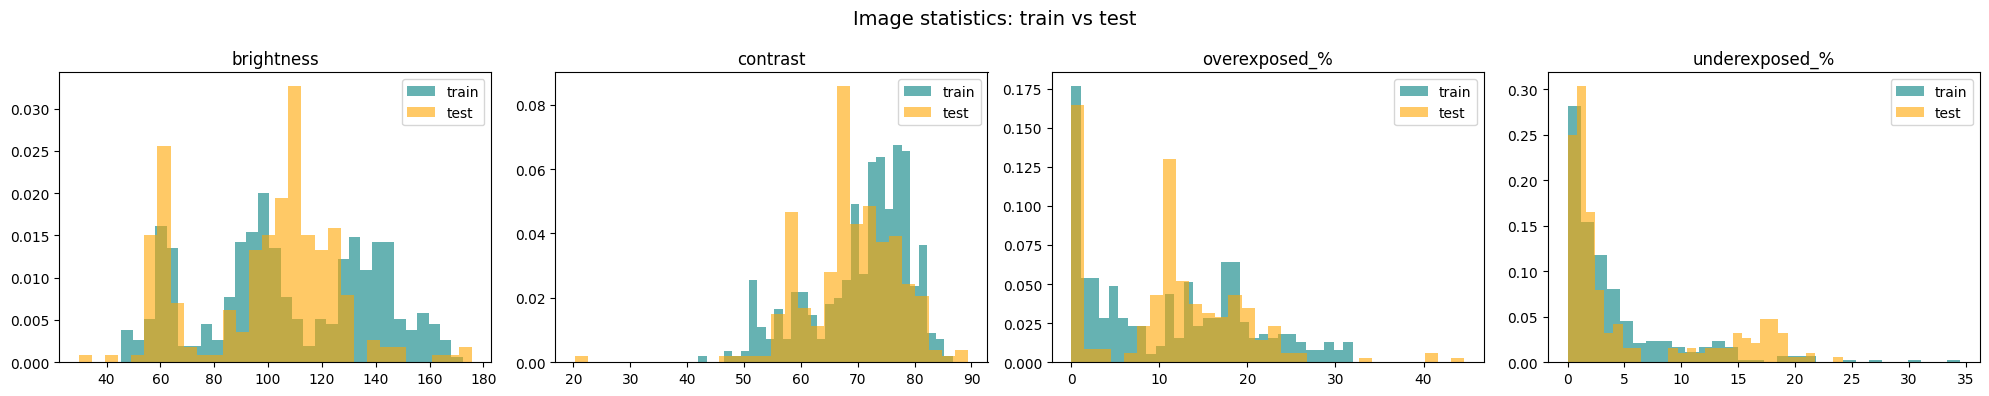

In [5]:
stats = []
for df, split_name in [(df_train, "train"), (df_test, "test")]:
    for i in range(len(df)):
        img, _ = load_pair(df.iloc[i])
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        stats.append({"split": split_name, "id": i,
                      "brightness": gray.mean(),
                      "contrast": gray.std(),
                      "overexposed_%": (gray >= 250).mean() * 100,
                      "underexposed_%": (gray <= 15).mean() * 100})
df_stats = pd.DataFrame(stats)

# Median and quartiles per split
display(df_stats.groupby("split")[["brightness", "contrast", "overexposed_%", "underexposed_%"]]
        .describe(percentiles=[0.25, 0.5, 0.75]).T.round(1))

print(f"Images with more than 5% overexposed pixels: {(df_stats['overexposed_%'] > 5).mean() * 100:.0f}%")
print(f"Dark images (mean brightness < 80):          {(df_stats['brightness'] < 80).mean() * 100:.0f}%")
print(f"Low-contrast images (std < 40):              {(df_stats['contrast'] < 40).mean() * 100:.1f}%")

# Histograms train vs test
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ["brightness", "contrast", "overexposed_%", "underexposed_%"]):
    for split_name, color in [("train", "teal"), ("test", "orange")]:
        ax.hist(df_stats[df_stats.split == split_name][col], bins=30, alpha=0.6,
                color=color, label=split_name, density=True)
    ax.set_title(col)
    ax.legend()
plt.suptitle("Image statistics: train vs test", fontsize=14)
plt.tight_layout()
plt.show()

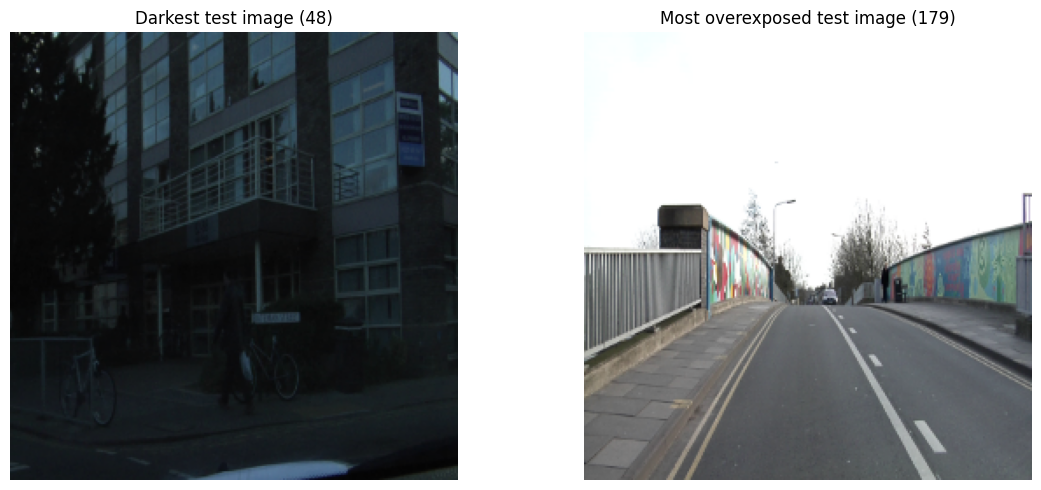

In [6]:
test_stats = df_stats[df_stats.split == "test"]
darkest = int(test_stats.loc[test_stats["brightness"].idxmin(), "id"])
brightest = int(test_stats.loc[test_stats["overexposed_%"].idxmax(), "id"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, idx, title in [(axes[0], darkest, "Darkest test image"),
                       (axes[1], brightest, "Most overexposed test image")]:
    img, _ = load_pair(df_test.iloc[idx])
    ax.imshow(img)
    ax.set_title(f"{title} ({idx})")
    ax.axis("off")
plt.tight_layout()
plt.show()

**What we learn:** the global contrast is fine (only 0.2% of images have a low contrast), so the problem is not "the whole image is flat". The real problems are **local**: 67% of the images have more than 5% burnt-white pixels (mostly the sky), and 23% are dark with deep shadows (example: image 48).
The **test images are darker than the training ones**: the darkest quarter of the test set has a brightness of 73 vs 87 for train, and a peak of dark images around 60 appears only in test. The model is tested on lighting conditions it saw less during training, which may explain part of the gap between validation and test scores (notebooks 03 and 05).

This guides the choice of filters:
- **CLAHE** (local histogram equalisation on the L channel of Lab, so colours are kept): targets dark images and shadows.
- **Bilateral filter:** smooths noise but keeps edges, so SLIC can still follow object borders.
- **Gaussian and median filters:** classic smoothing filters, used as a reference.

## 3. Effect of the filters on the images
Each filter is applied to the same test images. We show before / after examples and measure on 78 test images:
- **brightness** and **contrast** (as above),
- **noise level:** estimated standard deviation of the noise (lower = cleaner),
- **sharpness:** variance of the Laplacian (lower = more blurred edges).
A good filter for segmentation should reduce noise or fix lighting **without destroying the edges**.

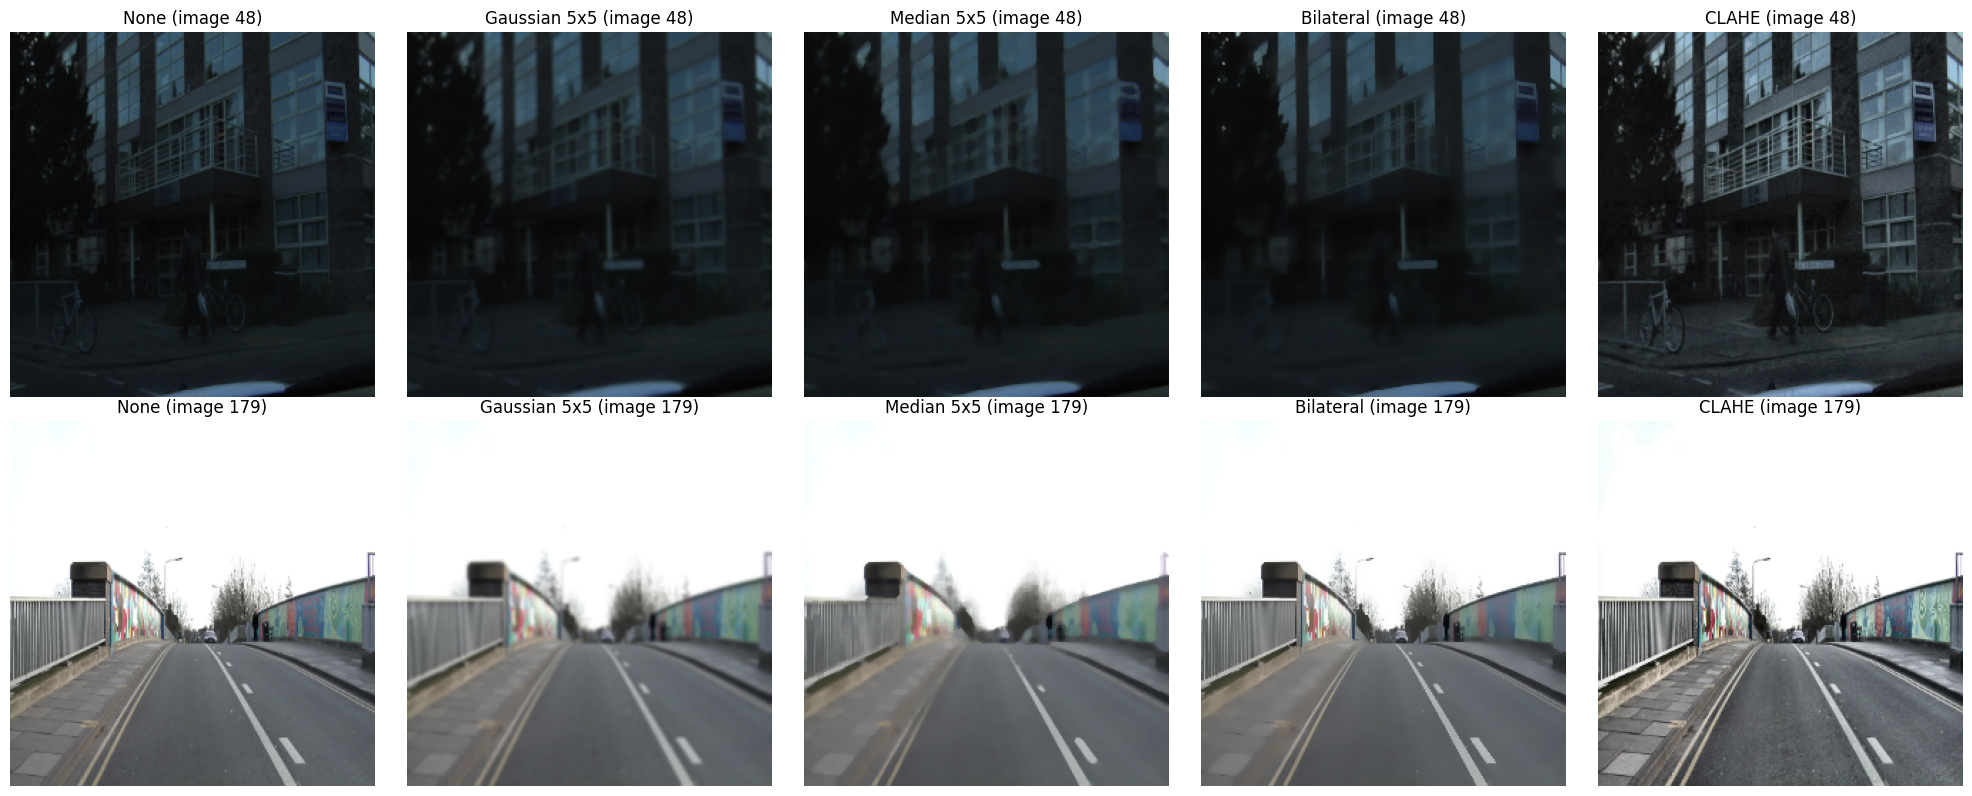

In [7]:
def clahe_lab(img, clip=2.0, tile=8):
    """CLAHE on the lightness channel only, so the colours are not changed."""
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)

PREPROCESSING = {
    "None": lambda img: img,
    "Gaussian 5x5": lambda img: cv2.GaussianBlur(img, (5, 5), 0),
    "Median 5x5": lambda img: cv2.medianBlur(img, 5),
    "Bilateral": lambda img: cv2.bilateralFilter(img, 9, 50, 50),   # keeps edges
    "CLAHE": clahe_lab,
}

# Before / after on a dark image and an overexposed image
fig, axes = plt.subplots(2, len(PREPROCESSING), figsize=(4 * len(PREPROCESSING), 8))
for r, idx in enumerate([darkest, brightest]):
    img, _ = load_pair(df_test.iloc[idx])
    for c, (name, f) in enumerate(PREPROCESSING.items()):
        axes[r, c].imshow(f(img))
        axes[r, c].set_title(f"{name} (image {idx})")
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()

In [8]:
quality = []
for name, f in PREPROCESSING.items():
    for i in range(0, len(df_test), 3):   # 1 test image out of 3, to be fast
        img, _ = load_pair(df_test.iloc[i])
        gray = cv2.cvtColor(f(img), cv2.COLOR_RGB2GRAY)
        quality.append({"Preprocessing": name,
                        "Brightness": gray.mean(),
                        "Contrast": gray.std(),
                        "Noise level": estimate_sigma(gray),
                        "Sharpness": cv2.Laplacian(gray, cv2.CV_64F).var()})
df_quality = pd.DataFrame(quality).groupby("Preprocessing", sort=False).mean().round(2)
df_quality

,Brightness,Contrast,Noise level,Sharpness
Preprocessing,,,,
None,98.11,68.59,1.94,2508.09
Gaussian 5x5,98.12,66.02,0.38,81.63
Median 5x5,97.93,67.62,0.50,325.29
Bilateral,98.07,68.21,0.61,2162.67
CLAHE,112.77,67.38,4.24,4544.36


**What we learn:**
- **Gaussian and median** remove the noise (1.94 → 0.38 / 0.50) but destroy the edges (sharpness 2508 → 82 / 325): on image 179 the median filter almost erases the road markings. Bad for segmentation, where borders matter.
- **Bilateral** removes almost as much noise (0.61) while keeping the edges (sharpness 2163): the best compromise for smoothing.
- **CLAHE** brightens dark areas (98 → 113) and reveals hidden objects (the balcony, bicycles and pedestrian of image 48), but it doubles the noise (1.94 → 4.24).
- **No filter can fix overexposure** (image 179): pixels at 255 have lost their information at capture time.

## 4. Effect on the segmentation
Same classical method as notebook 05 (400 superpixels, balanced Random Forest). For each filter, the filter is applied to **all** images (train, val and test), the Random Forest is retrained, and we measure the mIoU on validation and test.
We keep 4 settings (None, Gaussian, Bilateral, CLAHE) because each one takes 3-5 minutes on Colab.

In [9]:
def extract_with_preprocessing(df, preprocess, n_segments=400):
    """Same as extract_split of notebook 05, with a filter applied first."""
    X_list, y_list, segs, masks = [], [], [], []
    for i in range(len(df)):
        img, mask = load_pair(df.iloc[i])
        img = preprocess(img)
        seg = slic(img, n_segments=n_segments, compactness=10, start_label=0)
        X_list.append(superpixel_features(img, seg))
        y_list.append(superpixel_labels(seg, mask))
        segs.append(seg)
        masks.append(mask)
    return X_list, y_list, segs, masks

rows = []
for name in ["None", "Gaussian 5x5", "Bilateral", "CLAHE"]:
    t0 = time.time()
    f = PREPROCESSING[name]
    tr = extract_with_preprocessing(df_train, f)
    va = extract_with_preprocessing(df_val, f)
    te = extract_with_preprocessing(df_test, f)

    X_tr, y_tr = stack_training(tr[0], tr[1])
    rf = make_forest("balanced").fit(X_tr, y_tr)

    val_miou = evaluate(predict_masks(rf, va[0], va[2]), va[3])[0]
    test_miou, test_iou, test_acc, _ = evaluate(predict_masks(rf, te[0], te[2]), te[3])
    rows.append({"Preprocessing": name, "Val mIoU": round(val_miou, 4), "Test mIoU": round(test_miou, 4),
                 "Test pixel acc": round(test_acc, 4),
                 "Pole IoU": round(test_iou[2], 3), "Pavement IoU": round(test_iou[4], 3),
                 "Pedestrian IoU": round(test_iou[9], 3)})
    print(f"{name:<14} val mIoU = {val_miou:.4f} | test mIoU = {test_miou:.4f} ({time.time() - t0:.0f} s)")

df_pp = pd.DataFrame(rows)
df_pp

None           val mIoU = 0.4015 | test mIoU = 0.3333 (204 s)
Gaussian 5x5   val mIoU = 0.3878 | test mIoU = 0.3294 (212 s)
Bilateral      val mIoU = 0.3915 | test mIoU = 0.3367 (214 s)
CLAHE          val mIoU = 0.3829 | test mIoU = 0.3202 (199 s)


,Preprocessing,Val mIoU,Test mIoU,Test pixel acc,Pole IoU,Pavement IoU,Pedestrian IoU
0,None,0.4015,0.3333,0.7572,0.004,0.218,0.150
1,Gaussian 5x5,0.3878,0.3294,0.7512,0.008,0.217,0.161
2,Bilateral,0.3915,0.3367,0.7608,0.003,0.232,0.146
3,CLAHE,0.3829,0.3202,0.7493,0.004,0.153,0.144


**What we learn:** on the original images, no preprocessing improves the classical method. On validation (where we choose), "None" is the best (0.402) and all filters lose 1 to 2 points. On test, the bilateral filter is +0.3 point, which is too small to be meaningful and is not confirmed on validation. **We therefore keep no preprocessing for this method.**
- **CLAHE is the worst (test 0.320)** and pavement drops from 0.218 to 0.153: pavement and road already have almost the same colour, and CLAHE adds grain (noise × 2) and changes the colour and texture statistics the Random Forest used to separate them.
- **Pole and pedestrian IoU do not change:** their problem is the size of the superpixels, not the image quality, so preprocessing cannot fix it.
- Why so little effect: CamVid noise is low (σ ≈ 1.9) and averaging inside each superpixel already removes most of it, and the HSV / Lab colour features already separate brightness from colour.

**Conclusion for slide 5:** we measured the real problems of the data (local overexposure, dark images, darker test set), chose filters that target them, and showed their effect on the images. For this method, the limits are thin objects and missing context, not image quality. Preprocessing should matter more when images are degraded: this is tested in the robustness study.